# Age, risk willingness and liquid-budget resilience
## Integrated household evidence and allocation validation
**November 20, 2026 | Employer research handoff | Exploratory empirical study**

We investigate whether age predicts reported financial risk willingness and short-term financial resilience, whether the age relationship survives financial controls and alternative measurements, and whether household resources improve portfolio decisions. We combine four US Survey of Consumer Finances waves, independent Italian and Indian evidence, official European aggregates, and matched public/WRDS return experiments.

**Principal results.** Older US households report lower willingness. Age improves held-out willingness and liquidity predictions in all three chronological tests. The positive age gradient in liquidity does not imply a general increase in loss capacity: it depends on wealth, income composition and the specified shock. In 2025, an apparent older-age advantage under a wage interruption disappears after controlling for the earned-income share. The corrected WRDS age-plus-flow rule has no established CE advantage over the age-only rule. International evidence supports several country-specific observations, but not a harmonized country ranking.

This notebook reads aggregate artifacts only and runs without a WRDS account. It contains the analysis, figures, source links and boundaries needed to interpret the findings. Recomputing licensed market experiments requires independently entitled data access. The published-method reconstruction and earlier reports remain dated evidence; this report records the subsequent corrections and extensions.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

HERE = Path.cwd()
if not (HERE / 'design.json').exists():
    raise RuntimeError('Run this notebook from its own report directory.')
WRDS = HERE.parent / 'wrds_validation_2026_11_19'
PRIOR = HERE / 'evidence_prior'
FIG = HERE / 'figures'
FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.facecolor': 'white'})
def read(name): return pd.read_csv(HERE / name)
def save(name):
    plt.savefig(FIG / (name + '.png'), dpi=180, bbox_inches='tight')
    plt.savefig(FIG / (name + '.svg'), bbox_inches='tight')
    plt.show()
age = read('budget_age_contrasts.csv')
profiles = read('budget_age_profiles.csv')
transport = read('age_out_of_wave_scores.csv')
associations = read('willingness_budget_adjusted.csv')
scores = read('wrds_household_policy_scores.csv')
rules = read('wrds_household_rule_selection.csv')


## 1. Data selection and published foundations

The **SCF** is the primary dataset because it jointly observes financial-risk responses, detailed asset and liability balances, income components, demographics, five imputations, and official replicate weights. This allows willingness and liquid resources to be measured in the same households. We use reference-person ages 20-89 in 2016, 2019, 2022 and 2025. These are repeated cross-sections; age contrasts do not estimate within-person aging or isolate age, period and cohort effects. Sources: [SCF documentation](https://www.federalreserve.gov/econres/scf-documentation.htm), [2025 variable outline](https://www.federalreserve.gov/econres/files/scfoutline.2025.pdf), [2025 survey report](https://www.federalreserve.gov/publications/files/scf26.pdf).

[Bhutta and Dettling (2018)](https://www.federalreserve.gov/econres/notes/feds-notes/assessing-families-liquid-savings-using-the-survey-of-consumer-finances-20181119.html) motivates the expense-based liquidity measure. Our 2016 reconstruction gives **41.02%** and **30.17%** with three/six months of accessible resources, versus published **40%/28%**. This is an approximate reconstruction, not an exact replication: expense imputations, household-age definitions and public data vintages differ. The accompanying crosswalk records the deviations.

Other foundations include [Kim, Hanna and Ying (2021)](https://doi.org/10.1891/JFCP-19-00022) for SCF risk-item measurement; [Dohmen et al. (2017)](https://doi.org/10.1111/ecoj.12322) for life-course versus cross-sectional interpretation; [Lusardi, Schneider and Tufano (2011)](https://www.nber.org/papers/w17072) for shock-specific fragility; and [Kaplan, Violante and Weidner (2014)](https://www.nber.org/papers/w20073) for liquid versus illiquid wealth. Their structural or panel estimates are not reproduced by these cross-sectional exercises.

**Published results versus new work.** We check the Bhutta-Dettling descriptive benchmarks approximately, reproduce SEBI rounded risk-response benchmarks, and implement the official Italian variance convention. Our stress ledger, stress magnitudes, net-income factors and reserve threshold are investigator-defined scenarios. No cited paper supplies a validated universal formula for investment risk capacity.

In [2]:
display(read('household_sample_audit.csv'))
display(pd.read_csv(PRIOR / 'published_reconstruction.csv'))
display(pd.read_csv(PRIOR / 'measurement_crosswalk.csv'))


,year,households,implicates,replicates,missing_primary_expense,portfolio_zero_share,income_excludes,expense_definition
0,2016,6194,5,999,0,0.800292,"interest/dividends, capital gains and PENACCTWD",approximate reconstruction
1,2019,5719,5,999,0,0.794191,"interest/dividends, capital gains and PENACCTWD",approximate reconstruction
2,2022,4557,5,999,1,0.729738,"interest/dividends, capital gains and PENACCTWD",approximate reconstruction
3,2025,4325,5,999,0,0.757371,"interest/dividends, capital gains and PENACCTWD",reported


,group,threshold_months,published,reconstructed,difference_pp,status
0,All ages,3,0.40,0.410183,1.018255,Approximate: all ages; public data vintage and...
1,All ages,6,0.28,0.301720,2.171960,Approximate: all ages; public data vintage and...
2,Under35,3,0.29,0.300967,1.096668,Approximate: all ages; public data vintage and...
3,Under35,6,0.16,0.166953,0.695335,Approximate: all ages; public data vintage and...
4,Age35-55,3,0.33,0.350318,2.031760,Approximate: all ages; public data vintage and...
5,Age35-55,6,0.21,0.236554,2.655360,Approximate: all ages; public data vintage and...
6,Over55,3,0.50,0.515128,1.512754,Approximate: all ages; public data vintage and...
7,Over55,6,0.39,0.423547,3.354692,Approximate: all ages; public data vintage and...


,dataset,construct,source_fields,construction,interpretation
0,US SCF,Willingness,X7557; X3014,Observed 0-10 score (-1 is substantive zero); ...,"Reported preference, not loss capacity"
1,US SCF,Original liquidity ratio,LIQ; NORMINC,12 * LIQ / NORMINC,Investigator-defined income normalization; not...
2,US SCF,Expense-based accessible-assets ratio,LIQ + STOCKS + BOND + NMMF; reconstructed mont...,Accessible assets / monthly recurring expenses,Approximate Bhutta-Dettling reconstruction; ma...
3,US SCF 2025,Direct spending alternative,TOTSPENDNH; RENT; TPAY,Assets / (TOTSPENDNH / 12 + RENT + TPAY),New spending question; different scope from re...
4,US SHED,Direct emergency fund,EF1,Self-reported savings cover three months of ex...,Expense-linked self-report; not a full loss-ca...
5,Italy SHIW,Willingness,RISFIN,Categories 1-3 versus capital-protection categ...,Four-category financial willingness; wording d...
6,Italy SHIW,Expense-based buffer,AF1; CN; YL2; YCA2,12 * AF1 / (CN - YL2 - YCA2),Deposits include certificates; cash expenditur...
7,India SEBI,Willingness,QRT,Moderate/high-risk responses versus preservati...,Observed categories; no assumption of equal ca...
8,India SEBI,Age,Life_Stage,Gen Z / Millennials / Generation X / Baby Boomers,No artificial exact ages assigned; age is MEP ...
9,India SEBI,Saving allocation,Q1M grids,Monthly allocation flow,Not used as a stock of assets or capacity measure


## 2. Measures and estimation

**Observed willingness.** The primary binary response is $W=1\{X3014\in\{1,2,3\}\}$, versus no financial risk. The 0-10 response X7557 is retained as a secondary score; its substantive -1 code is recoded to zero. Willingness is not inferred from asset holdings and is never transformed into a CRRA coefficient.

**Resource scope.** Cash is LIQ. The taxable marketable portfolio is STOCKS + BOND + NMMF. These definitions exclude retirement balances, housing, CDs and savings bonds. A zero taxable portfolio is not equivalent to owning no investments. In 2025, 75.74% have zero balances in these narrowly defined marketable categories.

**Monthly outlays.** The primary 2025 denominator is $E=TOTSPENDNH/12+RENT+TPAY$. The spending question excludes rent and mortgage/loan payments; the added fields restore those cash outlays. Earlier waves use the approximate published recurring-expense reconstruction. Common-reconstruction and age-independent medical imputations are sensitivities. Debt principal is an outlay, not consumption utility.

**Recurring income.** Earned income is nonnegative wages plus business/farm income. Other income is nonnegative $(SSRETINC-PENACCTWD)$ plus transfers. Retirement-account draws are excluded. Interest, dividends and capital gains are excluded to avoid counting modeled portfolio returns twice. We compare gross-to-net factors 0.70, 0.85 and 1.00; these are assumptions, not estimated taxes.

**Survey inference.** Point estimates average five imputations. Covariance is the sample covariance of 999 official bootstrap replicate estimates on implicate 1, plus $1.2$ times the covariance across five imputation estimates, following the Federal Reserve convention. Normal intervals are approximate. Age models are weighted linear probability models with piecewise-linear age knots at 45 and 65. We report age 75 minus age 30 contrasts with demographics, income/wealth, and additional earned-income-share adjustment. These are associations; financial adjustment can condition on pathways connecting age to resources. Intervals are pointwise unless a multiplicity adjustment is explicitly stated.

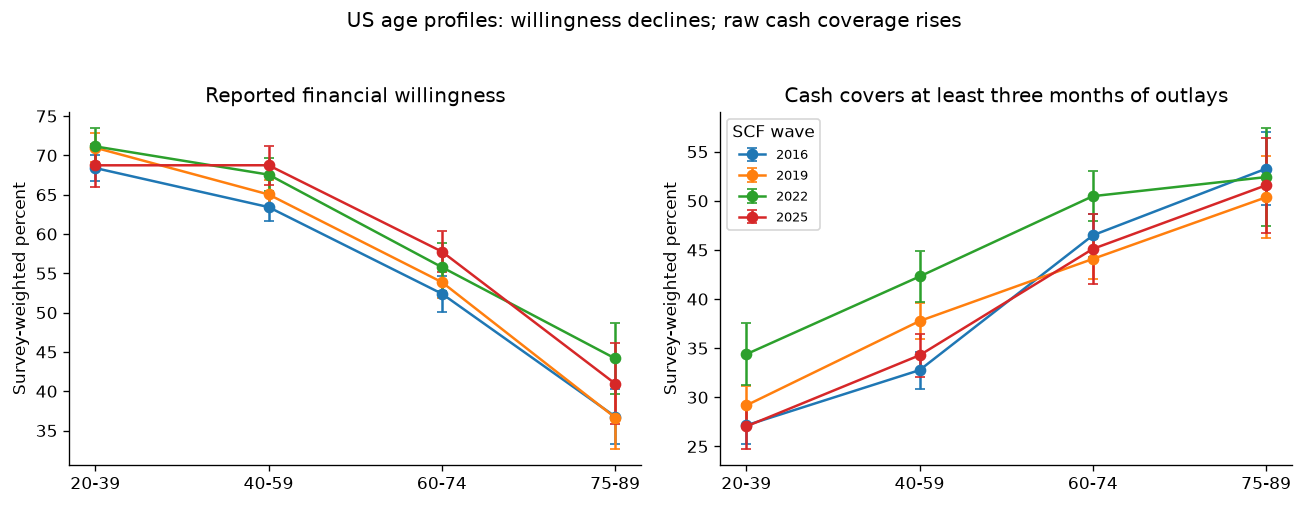

,year,specification,outcome,estimate,low,high
0,2016,Demographics,any_risk,-0.2299,-0.2599,-0.1999
1,2016,Demographics,cash_ge3,0.2480,0.2182,0.2778
7,2016,Income and wealth adjustment,any_risk,-0.3801,-0.4104,-0.3498
8,2016,Income and wealth adjustment,cash_ge3,-0.0252,-0.0554,0.0050
21,2019,Demographics,any_risk,-0.2572,-0.2881,-0.2263
22,2019,Demographics,cash_ge3,0.1922,0.1558,0.2287
28,2019,Income and wealth adjustment,any_risk,-0.3791,-0.4161,-0.3421
29,2019,Income and wealth adjustment,cash_ge3,-0.0495,-0.0856,-0.0134
42,2022,Demographics,any_risk,-0.1872,-0.2282,-0.1462
43,2022,Demographics,cash_ge3,0.2249,0.1844,0.2654


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, measure, title in zip(axes, ['any_risk', 'cash_ge3'], ['Reported financial willingness', 'Cash covers at least three months of outlays']):
    for year, group in profiles[profiles.variable.eq(measure)].groupby('year'):
        group = group.set_index('group').loc[['20-39','40-59','60-74','75-89']]
        ax.errorbar(range(4), group.estimate*100, yerr=group.se*196, marker='o', capsize=3, label=str(year))
    ax.set(xticks=range(4), xticklabels=['20-39','40-59','60-74','75-89'], ylabel='Survey-weighted percent', title=title)
axes[1].legend(title='SCF wave', fontsize=8)
fig.suptitle('US age profiles: willingness declines; raw cash coverage rises', y=1.04)
fig.tight_layout(); save('01_us_age_profiles')
display(age[age.outcome.isin(['any_risk','cash_ge3']) & age.specification.isin(['Demographics','Income and wealth adjustment'])][['year','specification','outcome','estimate','low','high']].round(4))


## 3. Does age predict outcomes in later surveys?

We fit weighted logistic models in earlier waves and evaluate them in the next wave: 2016 to 2019; 2016+2019 to 2022; and 2016+2019+2022 to 2025. Each training wave receives equal total weight. All five imputation models are fitted separately. Models are intercept-only, age spline, income/wealth, and income/wealth plus age. The liquidity target uses accessible assets and the **same age-independent reconstructed expense definition across waves**, avoiding the 2025 spending-question change. Later-wave descriptive outcomes had already been inspected in earlier analyses; this is a retrospective chronological test, not an untouched prospective lockbox.

**Result: age is predictive for both recorded outcomes in these held-out waves.** Adding age to income/wealth improves Brier loss in all six target/wave tests. Brier improvement means the financial model's mean squared probability error minus the age-augmented model's error; positive is better. We report log loss and AUC as additional diagnostics. Holm adjustment covers the six incremental-age tests. Survey intervals condition on fitted training models and exclude full training-sample uncertainty. These are cross-sectional transport tests, not forecasts of the same person's aging. Income/wealth predictors share ingredients with the liquidity target; this is predictive evaluation, not independent validation of a latent capacity construct.

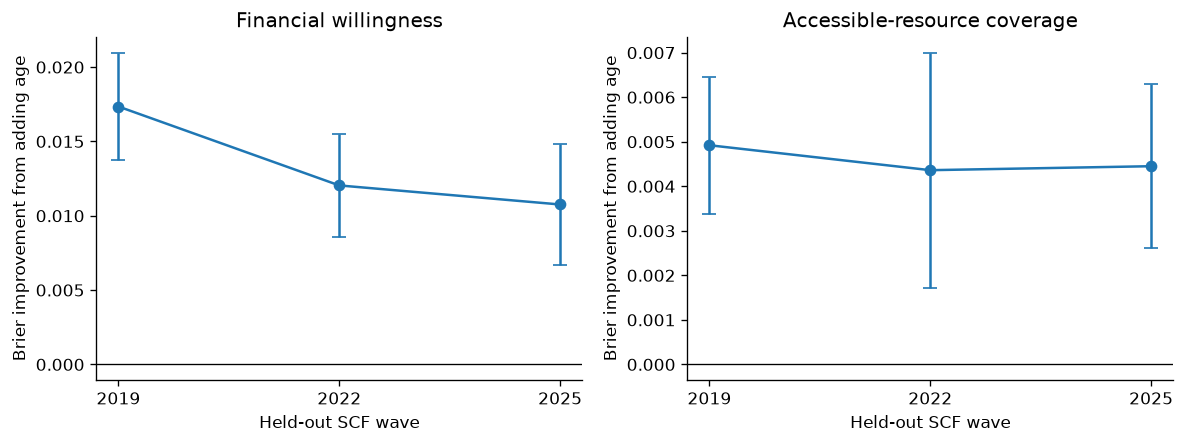

,train_years,test_year,target,estimate,low,high,p_holm_six_incremental_age_tests
12,2016,2019,any_risk,0.017347,0.013731,0.020962,0.000000
26,2016,2019,accessible_noage_ge3,0.004921,0.003386,0.006456,0.000000
40,2016+2019,2022,any_risk,0.012039,0.008554,0.015525,0.000000
54,2016+2019,2022,accessible_noage_ge3,0.004361,0.001725,0.006997,0.001183
68,2016+2019+2022,2025,any_risk,0.010758,0.006666,0.014850,0.000001
82,2016+2019+2022,2025,accessible_noage_ge3,0.004450,0.002610,0.006291,0.000004


,target,model,metric,estimate
56,any_risk,Intercept,Brier,0.2348
58,any_risk,Intercept,AUC,0.5000
59,any_risk,Age,Brier,0.2262
61,any_risk,Age,AUC,0.5975
62,any_risk,Financial,Brier,0.1890
64,any_risk,Financial,AUC,0.7667
65,any_risk,Financial + age,Brier,0.1782
67,any_risk,Financial + age,AUC,0.7918
70,accessible_noage_ge3,Intercept,Brier,0.2472
72,accessible_noage_ge3,Intercept,AUC,0.5000


In [4]:
incremental = transport[transport.model.eq('Financial vs financial + age')]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, target, title in zip(axes, ['any_risk','accessible_noage_ge3'], ['Financial willingness','Accessible-resource coverage']):
    q = incremental[incremental.target.eq(target)]
    ax.errorbar(q.test_year, q.estimate, yerr=q.se*1.96, marker='o', capsize=4)
    ax.axhline(0, color='black', linewidth=.8)
    ax.set(title=title, xlabel='Held-out SCF wave', ylabel='Brier improvement from adding age', xticks=[2019,2022,2025])
fig.tight_layout(); save('02_chronological_prediction')
display(incremental[['train_years','test_year','target','estimate','low','high','p_holm_six_incremental_age_tests']].round(6))
display(transport[transport.test_year.eq(2025) & transport.metric.isin(['Brier','AUC'])][['target','model','metric','estimate']].round(4))


## 4. Improve measurement by stating the shock

We test whether accessible resources can pay one year of cash outlays and retain $3E$. At time zero, a hypothetical 60/40 taxable portfolio loses 40% on stocks and 10% on bonds; cash is intact. Earned income stops for six months. Pensions and transfers continue in the primary scenario; a sensitivity stops **all** recurring income. No new borrowing or assumed asset appreciation is allowed. Income subsequently returning cannot erase a previously missed payment.

For household $i$, initialize $A_{i0}=LIQ_i+P_i(1-0.6(0.4)-0.4(0.1))$. Each month, available resources are $R_{it}=A_{it}+0.85Y_{it}/12$, funded outlays are $F_{it}=\min(E_i,R_{it})$, and $A_{i,t+1}=R_{it}-F_{it}$. Passing requires $F_{it}=E_i$ every month and $A_{i,12}\geq3E_i$. These assumptions define a **liquid-budget stress test**, not a lifetime capacity scale, a historical pandemic scenario, or an estimated probability of unemployment.

**2025 result.** With income/wealth controls, the older-age contrast is +16.51 percentage points under earned-income interruption (95% interval +11.46 to +21.56). Adding earned-income share reduces it to +0.37 points (-6.43 to +7.17). Interrupting all income gives -3.59 points (-8.01 to +0.82) before that additional control. Thus continued nonlabor income explains the apparent age advantage under this particular shock; the exercise does not identify a causal mediation effect. A general claim that financial capacity increases with age is unsupported.

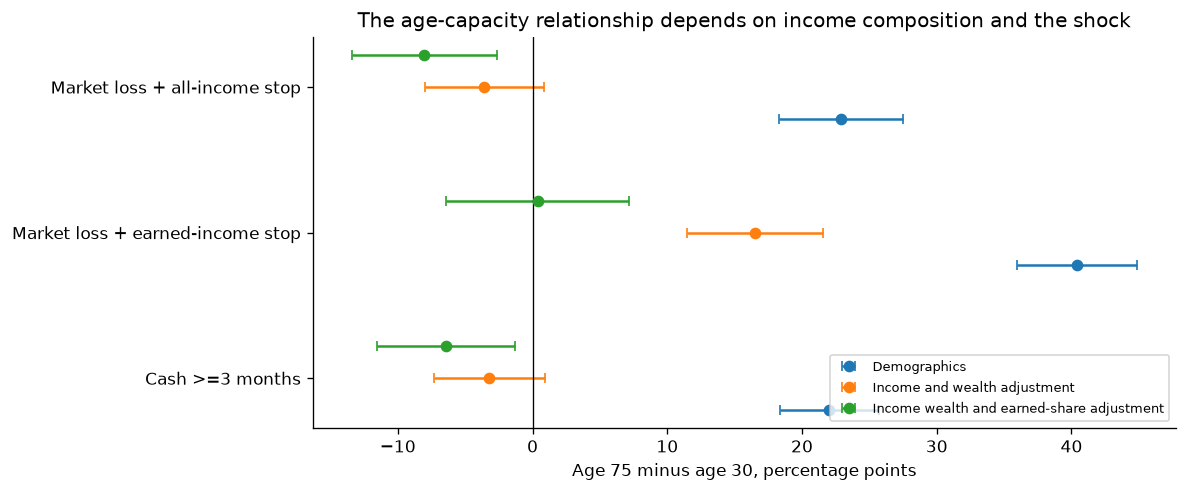

,specification,outcome,estimate,low,high
64,Demographics,cash_ge3,0.2203,0.1837,0.2570
66,Demographics,combined_stress_reserve,0.4038,0.3592,0.4485
69,Demographics,combined_all_income_interruption,0.2290,0.1832,0.2748
71,Income and wealth adjustment,cash_ge3,-0.0322,-0.0735,0.0090
73,Income and wealth adjustment,combined_stress_reserve,0.1651,0.1146,0.2156
76,Income and wealth adjustment,combined_all_income_interruption,-0.0359,-0.0801,0.0082
78,Income wealth and earned-share adjustment,cash_ge3,-0.0642,-0.1153,-0.0131
80,Income wealth and earned-share adjustment,combined_stress_reserve,0.0037,-0.0643,0.0717
83,Income wealth and earned-share adjustment,combined_all_income_interruption,-0.0804,-0.1340,-0.0267


In [5]:
q=age[age.year.eq(2025)&age.outcome.isin(['cash_ge3','combined_stress_reserve','combined_all_income_interruption'])]
labels={'cash_ge3':'Cash >=3 months','combined_stress_reserve':'Market loss + earned-income stop','combined_all_income_interruption':'Market loss + all-income stop'}
fig, ax=plt.subplots(figsize=(10,4.2))
for offset,(spec,g) in zip([-.22,0,.22],q.groupby('specification',sort=False)):
    g=g.set_index('outcome').loc[list(labels)]
    ax.errorbar(g.estimate*100,np.arange(3)+offset,xerr=g.se*196,fmt='o',capsize=3,label=spec)
ax.axvline(0,color='black',linewidth=.8)
ax.set(yticks=range(3),yticklabels=list(labels.values()),xlabel='Age 75 minus age 30, percentage points',title='The age-capacity relationship depends on income composition and the shock')
ax.legend(fontsize=8,loc='lower right');fig.tight_layout();save('03_shock_and_adjustment')
display(q[['specification','outcome','estimate','low','high']].round(4))


## 5. How are willingness and resilience related?

We regress directly observed willingness on each budget threshold, the age spline, demographics, log income and transformed net wealth. Meeting the cash threshold is positively associated with willingness in all four waves. In 2025 the adjusted difference is **+7.35 percentage points** (95% interval +4.36 to +10.34). Meeting the primary earned-interruption stress threshold is associated with only **+1.66 points** (-1.49 to +4.81) in 2025. Under all-income interruption the association is **+8.39 points** (+4.83 to +11.94). The relationship is therefore measurement- and shock-dependent. These conditional associations do not establish which variable causes the other, nor justify converting the survey response into a utility parameter.

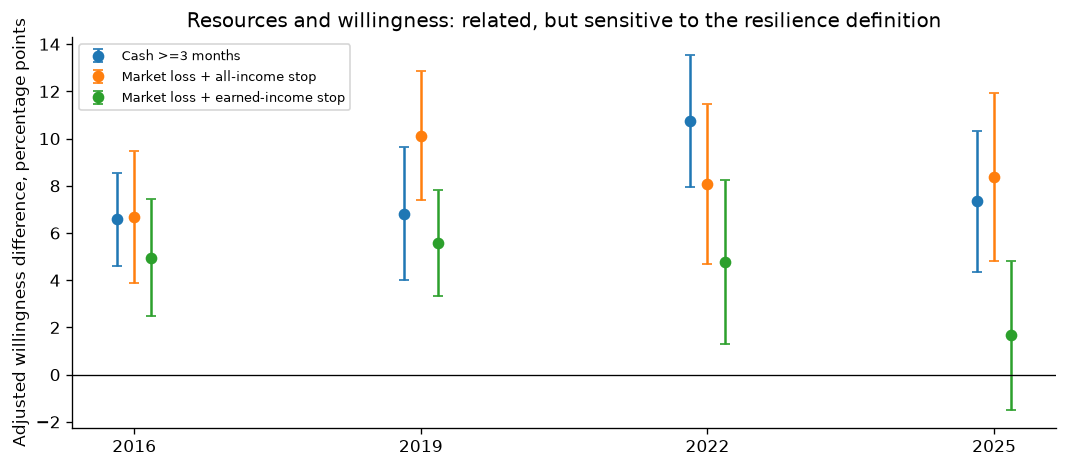

,year,measure,estimate,low,high
0,2016,cash_ge3,0.0658,0.0461,0.0854
1,2016,combined_stress_reserve,0.0495,0.0247,0.0744
2,2016,combined_all_income_interruption,0.0669,0.0389,0.0948
3,2019,cash_ge3,0.0682,0.0402,0.0963
4,2019,combined_stress_reserve,0.0558,0.0333,0.0784
5,2019,combined_all_income_interruption,0.1013,0.0739,0.1287
6,2022,cash_ge3,0.1075,0.0796,0.1355
7,2022,combined_stress_reserve,0.0478,0.0131,0.0824
8,2022,combined_all_income_interruption,0.0808,0.0470,0.1146
9,2025,cash_ge3,0.0735,0.0436,0.1034


In [6]:
fig,ax=plt.subplots(figsize=(9,4))
for j,(measure,g) in enumerate(associations.groupby('measure')):
    ax.errorbar(g.year+(j-1)*.18,g.estimate*100,yerr=g.se*196,fmt='o',capsize=3,label=labels.get(measure,measure))
ax.axhline(0,color='black',linewidth=.8)
ax.set(xticks=[2016,2019,2022,2025],ylabel='Adjusted willingness difference, percentage points',title='Resources and willingness: related, but sensitive to the resilience definition')
ax.legend(fontsize=8);fig.tight_layout();save('04_willingness_resilience_association')
display(associations[['year','measure','estimate','low','high']].round(4))


### 5.1 Independent prospective criterion: SHED emergency savings and later unpaid bills

We reran the existing [Federal Reserve SHED](https://www.federalreserve.gov/consumerscommunities/shed_data.htm) analysis in the integrated evidence folder. Official documentation permits linking the same respondent by shedid and supplies a 2025 panel weight for 2024 recontacts ([FAQ](https://www.federalreserve.gov/consumerscommunities/shed-faqs.htm), [2025 codebook](https://www.federalreserve.gov/consumerscommunities/files/SHED_2025codebook.pdf)). In 4,299 matched eligible respondents, reporting a three-month emergency fund in 2024 is associated with **6.72 percentage points fewer unpaid bills in 2025** after demographics, income, baseline unpaid bills and income stability (HC3 interval -9.17 to -4.27). Weighted observed unpaid-bill rates are 24.00% without the baseline fund and 5.87% with it. These unadjusted group rates are not treatment effects.

Five-fold respondent-held-out prediction reduces Brier loss from **0.097078 to 0.096140** and log loss from 0.324957 to 0.320628 when the fund indicator is added. This is prospective criterion evidence for an emergency-fund proxy, not validation of the new SCF stress formula or of lifetime investment-loss capacity. HC3 uncertainty is model-based rather than a full complex-survey calculation; no interval is claimed for the cross-validation score difference.

The 2018-2019 within-person emergency-fund-change/willingness-change coefficient is **0.059** on the 0-10 willingness scale (interval -0.142 to +0.260), based on 4,211 retained respondents without a longitudinal weight. It does not establish that improving liquidity changes willingness. Cross-sectional association and prospective hardship prediction should not be described as causal preference effects.

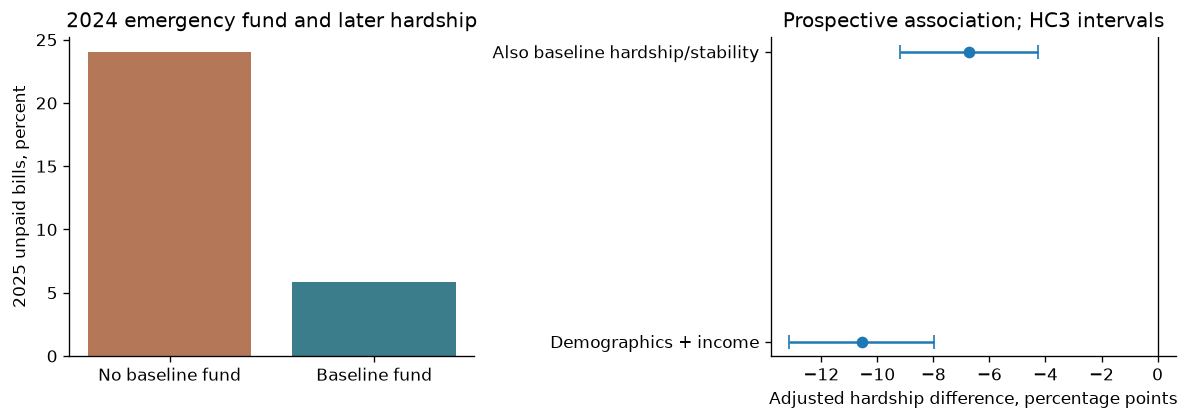

,measure,adjustment,estimate,se,low,high,p_normal,n
0,emergency_fund,Demographics + income,-0.10558,0.01319,-0.13143,-0.07972,0.0,4299
1,emergency_fund,Also baseline unpaid bills + income stability,-0.06722,0.01251,-0.09175,-0.04270,0.0,4299
2,own_savings_ge2000,Also baseline unpaid bills + income stability,-0.08706,0.01196,-0.11049,-0.06362,0.0,4299


,model,weighted_Brier,weighted_log_loss,n,folds
0,Baseline,0.097078,0.324957,4299,5
1,Add emergency fund,0.096140,0.320628,4299,5


{'estimate': 0.05917068371555693,
 'se': 0.10257312747035686,
 'low': -0.14187264612634254,
 'high': 0.2602140135574564,
 'p_normal': 0.5640317324180071,
 'n': 4211,
 'dataset': 'SHED 2018-2019 matched respondents',
 'weighting': 'Unweighted retained-panel association',
 'transitions': {'-1.0': 296, '0.0': 3541, '1.0': 374}}

In [7]:
shed=HERE/'evidence_shed'
prospective=pd.read_csv(shed/'shed_prospective.csv')
groups=pd.read_csv(shed/'shed_prospective_groups.csv')
cv=pd.read_csv(shed/'shed_prospective_cv.csv')
fig,axes=plt.subplots(1,2,figsize=(10,3.6))
axes[0].bar(['No baseline fund','Baseline fund'],groups.next_year_unpaid_rate*100,color=['#b47859','#3b7d8a'])
axes[0].set(ylabel='2025 unpaid bills, percent',title='2024 emergency fund and later hardship')
q=prospective[prospective.measure.eq('emergency_fund')]
axes[1].errorbar(q.estimate*100,range(len(q)),xerr=q.se*196,fmt='o',capsize=4)
axes[1].axvline(0,color='black',linewidth=.8)
axes[1].set(yticks=[0,1],yticklabels=['Demographics + income','Also baseline hardship/stability'],xlabel='Adjusted hardship difference, percentage points',title='Prospective association; HC3 intervals')
fig.tight_layout();save('08_shed_prospective_criterion')
display(prospective.round(5));display(cv.round(6))
display(json.loads((shed/'shed_within_person.json').read_text()))


## 6. Connect household budgets to market scenarios

We calibrate **16 survey-weighted mean templates** by four age bands, cash above/below three months of outlays, and reported willingness/no risk. Inputs are jointly observed SCF cash, taxable investments, earnings, nonlabor income and outlays. Mean templates preserve linear budgets but are not representative individual households. Their nonlinear success probabilities must not be aggregated into population estimates. Actual household-level deterministic stress prevalence, estimated with survey uncertainty, is exported separately. Skewed wealth can make a cell's mean far more resilient than many of its members.

For each template we generate three-asset real returns (US stocks, Treasury bills and 10-year Treasuries), using matched public and WRDS histories, May 1953-December 2024. A stationary bootstrap uses a fixed 12-month mean block, 2,000 fitting paths and 5,000 disjoint evaluation paths. One-, five- and ten-year scenarios share paths within each dataset. Real income/outlays are frozen except the specified six-month interruption; there is no estimated career, retirement, mortality, tax or behavioral transition model. These are forward scenarios conditional on 2025 budgets, not historical trades using future household observations.

Benchmarks are all cash, 60/40, an age glidepath, and six months of initial cash plus 60/40. The budget-constrained rule sets aside three months of initial outlays, tests six equity fractions in the remaining portfolio, and selects the highest median terminal resources among candidates whose training joint funding/reserve probability has a simultaneous one-sided 95% Bonferroni-Wilson lower bound of at least 90%. If no candidate qualifies, it minimizes mean unmet outlays. Independent paths evaluate selection; executed trades pay a 5bp half-spread. The initial allocation is endowed without an implementation-turnover charge; no claim of fully net implementation performance is made. This is a budget rule, **not a preference-consistent recommendation**: reported willingness is retained for grouping, not used to impose an estimated investment mandate.

Under WRDS compound stress at ten years, **12 of 16 mean templates** have a feasible training candidate and an evaluation joint-probability lower bound above 90%; four do not. The budget rule improves funding over the age glidepath in two templates and ties in the others, with paired conditional Monte Carlo intervals. All 16 income-maintained mean templates fund their outlays, demonstrating how favorable mean budgets and frozen income can be. These outcomes cannot establish a general welfare gain or validate individual suitability.

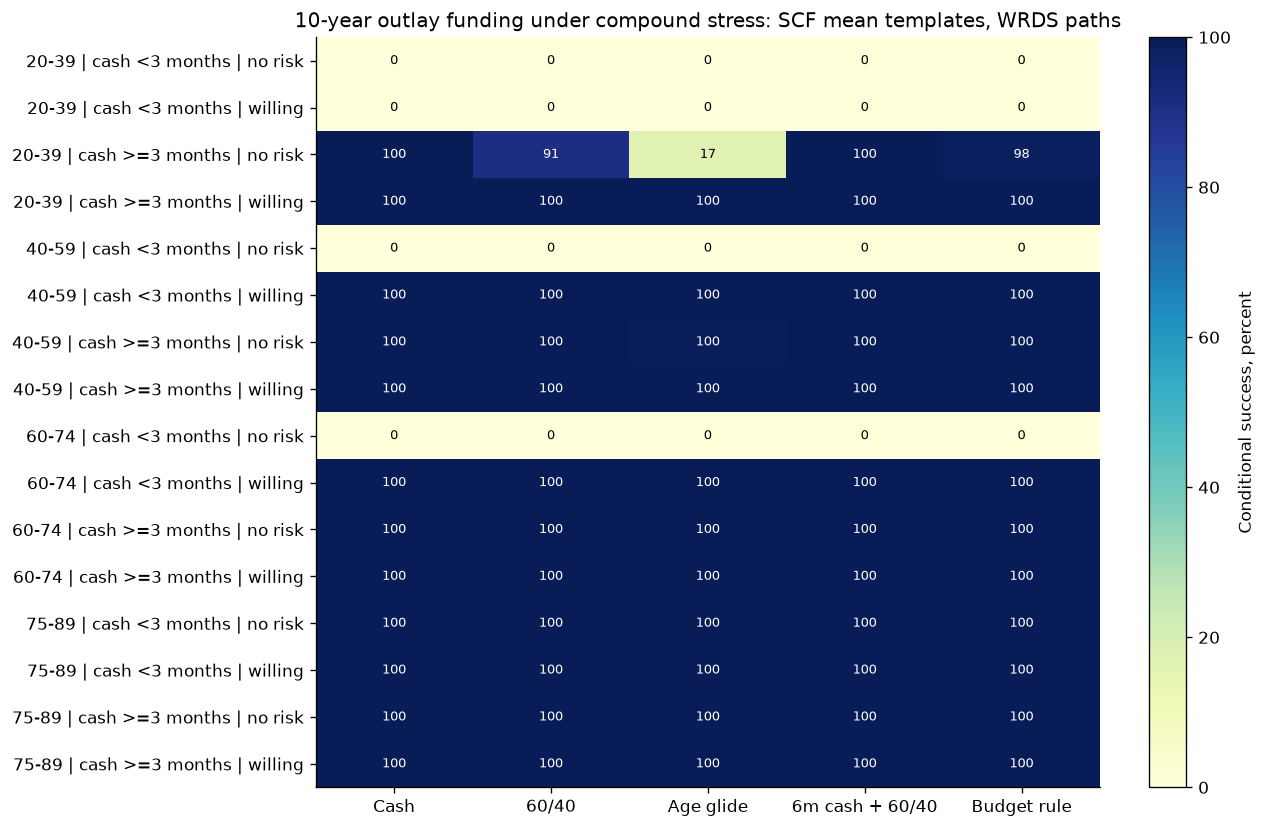

,profile_id,feasible_training_grid,selected_equity,selected_cash,training_joint_lower
5,20-39 | cash <3 months | no risk,False,0.0000,1.0000,0.0000
11,20-39 | cash <3 months | willing,False,0.0000,0.6747,0.0000
17,20-39 | cash >=3 months | no risk,True,0.6335,0.3665,0.9764
23,20-39 | cash >=3 months | willing,True,0.9213,0.0787,0.9971
29,40-59 | cash <3 months | no risk,False,0.0000,1.0000,0.0000
35,40-59 | cash <3 months | willing,True,0.7599,0.2401,0.9971
41,40-59 | cash >=3 months | no risk,True,0.6484,0.3516,0.9971
47,40-59 | cash >=3 months | willing,True,0.9621,0.0379,0.9971
53,60-74 | cash <3 months | no risk,False,0.0000,1.0000,0.0000
59,60-74 | cash <3 months | willing,True,0.9320,0.0680,0.9971


,profile_id,estimate,low,high
58,20-39 | cash <3 months | no risk,0.0000,0.0000,0.0000
118,20-39 | cash <3 months | willing,0.0000,0.0000,0.0000
178,20-39 | cash >=3 months | no risk,0.8132,0.8024,0.8240
238,20-39 | cash >=3 months | willing,0.0000,0.0000,0.0000
298,40-59 | cash <3 months | no risk,0.0000,0.0000,0.0000
358,40-59 | cash <3 months | willing,0.0000,0.0000,0.0000
418,40-59 | cash >=3 months | no risk,0.0040,0.0023,0.0057
478,40-59 | cash >=3 months | willing,0.0000,0.0000,0.0000
538,60-74 | cash <3 months | no risk,0.0000,0.0000,0.0000
598,60-74 | cash <3 months | willing,0.0000,0.0000,0.0000


min     max
scenario          horizon                
compound_stress   1       -0.0068  0.0048
                  5       -0.0068  0.0048
                  10      -0.0068  0.0048
income_maintained 1        0.0000  0.0000
                  5        0.0000  0.0000
                  10       0.0000  0.0000

In [8]:
q=scores[scores.horizon.eq(10)&scores.scenario.eq('compound_stress')]
order=['all_cash','sixty_forty','age_glide','six_month_cash_6040','budget_constrained']
heat=q.pivot(index='profile_id',columns='policy',values='outlay_success')[order]
fig,ax=plt.subplots(figsize=(11,7))
im=ax.imshow(heat.to_numpy()*100,vmin=0,vmax=100,cmap='YlGnBu',aspect='auto')
ax.set(xticks=range(5),xticklabels=['Cash','60/40','Age glide','6m cash + 60/40','Budget rule'],yticks=range(len(heat)),yticklabels=heat.index,title='10-year outlay funding under compound stress: SCF mean templates, WRDS paths')
for i in range(len(heat)):
    for j in range(5):
        v=heat.iloc[i,j]*100;ax.text(j,i,f'{v:.0f}',ha='center',va='center',fontsize=8,color='white' if v>65 else 'black')
fig.colorbar(im,ax=ax,label='Conditional success, percent');fig.tight_layout();save('05_template_funding')
display(rules[rules.horizon.eq(10)&rules.scenario.eq('compound_stress')][['profile_id','feasible_training_grid','selected_equity','selected_cash','training_joint_lower']].round(4))
paired=read('wrds_household_paired_differences.csv')
display(paired[paired.horizon.eq(10)&paired.scenario.eq('compound_stress')&paired.policy.eq('budget_constrained')&paired.metric.eq('outlay_success')][['profile_id','estimate','low','high']].round(4))
public=read('public_household_policy_scores.csv')
comparison=scores.merge(public,on=['profile_id','horizon','scenario','policy'],suffixes=('_wrds','_public'))
display(comparison.assign(source_difference=lambda d:d.outlay_success_wrds-d.outlay_success_public).groupby(['scenario','horizon']).source_difference.agg(['min','max']).round(4))


## 7. Audit nonlinear aggregation

The figure below compares the actual survey-weighted proportion of households passing the deterministic one-year stress with the pass/fail outcome of the mean template. A mean template can pass even when a substantial fraction of its source cell fails. This diagnostic prevents treating archetype simulations as nationally representative policy performance. Population results in Sections 2-5 use household-level observations and survey inference; Section 6 is explicitly a conditional archetype experiment.

C:\Users\13156\AppData\Local\Temp\ipykernel_54524\2134072488.py:16: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  ax.errorbar(gap.actual_household_pass_share*100,y,xerr=np.row_stack([(gap.actual_household_pass_share-gap.low)*100,(gap.high-gap.actual_household_pass_share)*100]),fmt='o',capsize=2,label='Actual households, survey estimate')


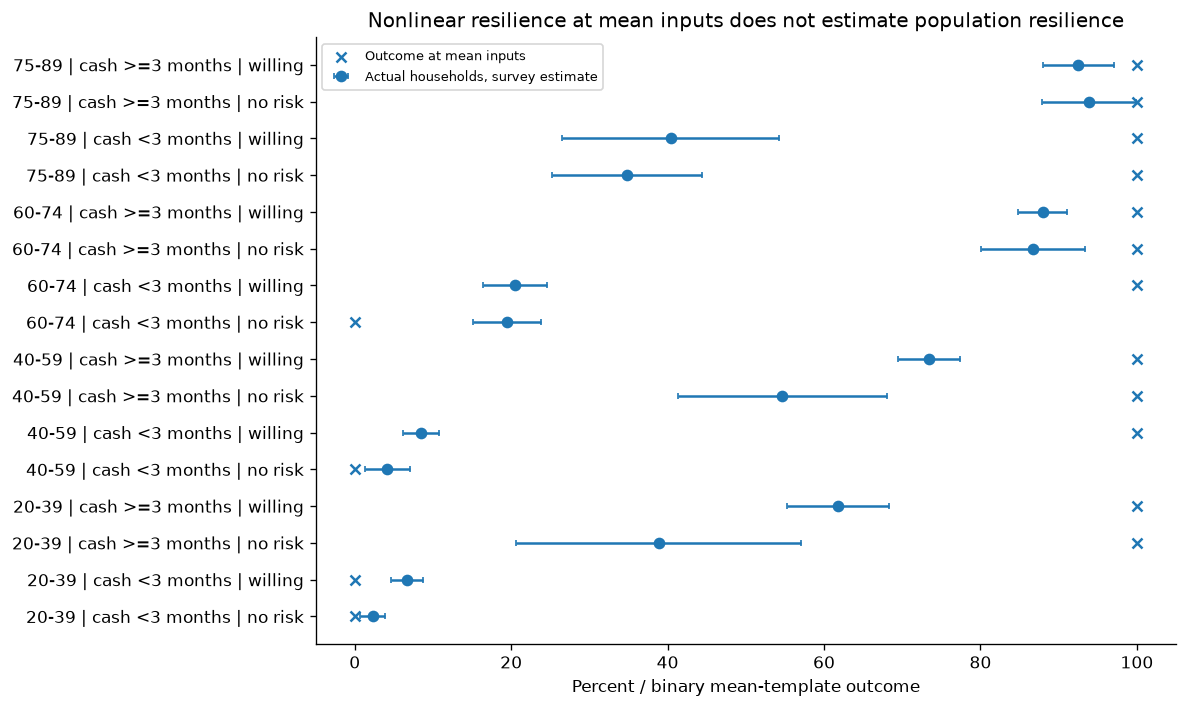

,actual_household_pass_share,low,high,mean_template_pass
profile_id,,,,
20-39 | cash <3 months | no risk,0.0227,0.0063,0.0391,0.0
20-39 | cash <3 months | willing,0.0666,0.0460,0.0871,0.0
20-39 | cash >=3 months | no risk,0.3885,0.2067,0.5702,1.0
20-39 | cash >=3 months | willing,0.6179,0.5527,0.6831,1.0
40-59 | cash <3 months | no risk,0.0415,0.0127,0.0703,0.0
40-59 | cash <3 months | willing,0.0848,0.0619,0.1078,1.0
40-59 | cash >=3 months | no risk,0.5468,0.4127,0.6808,1.0
40-59 | cash >=3 months | willing,0.7341,0.6944,0.7738,1.0
60-74 | cash <3 months | no risk,0.1945,0.1510,0.2381,0.0


In [9]:
actual=read('actual_household_cell_stress.csv')
actual=actual[actual.variable.eq('combined_stress_reserve')].set_index('group')
templates=read('household_templates.csv').set_index('profile_id')
initial=templates.cash+.72*templates.taxable_portfolio
unmet=np.zeros(len(templates));assets=initial.to_numpy().copy()
for month in range(12):
    income=.85*(templates.nonlabor_income+(templates.earned_income if month>=6 else 0))/12
    available=assets+income.to_numpy();funded=np.minimum(available,templates.expense_primary)
    unmet+=templates.expense_primary-funded;assets=available-funded
mean_pass=((unmet<1e-6)&(assets>=3*templates.expense_primary)).astype(float)
gap=actual.loc[templates.index,['estimate','low','high']].rename(columns={'estimate':'actual_household_pass_share'})
gap['mean_template_pass']=mean_pass
gap.to_csv(HERE/'nonlinear_aggregation_audit.csv')
fig,ax=plt.subplots(figsize=(10,6))
y=np.arange(len(gap))
ax.errorbar(gap.actual_household_pass_share*100,y,xerr=np.row_stack([(gap.actual_household_pass_share-gap.low)*100,(gap.high-gap.actual_household_pass_share)*100]),fmt='o',capsize=2,label='Actual households, survey estimate')
ax.scatter(gap.mean_template_pass*100,y,marker='x',label='Outcome at mean inputs')
ax.set(yticks=y,yticklabels=gap.index,xlabel='Percent / binary mean-template outcome',title='Nonlinear resilience at mean inputs does not estimate population resilience')
ax.legend(fontsize=8);fig.tight_layout();save('06_nonlinear_aggregation')
display(gap.round(4))


## 8. What did the corrected market study establish?

The earlier allocation study tested age/horizon and signed external cash flows using paired future paths. The initial +0.61% resources-CE result used mismatched universes: unused Treasury maturities changed the automatic bootstrap block length. The matched three-asset WRDS correction is **+0.1041%** versus the age-only rule, with a 95% paired interval **-0.0783% to +0.3289%**. This does not establish a CE improvement. Only **56% of 100 training-history refits** produce a positive difference; the central refit range is approximately -1.73% to +1.82%, conditional on a fixed future model.

At 5% annual real withdrawals, changing the Treasury source alone moves the best simulated spending-success probability from 89.23% to 90.71% in the 2002-2013 calibration. The matched all-CRSP 2002-2024 experiment reaches only 88.73%. Thus a universal 90%-success bond minimum is not supported. CE- and success-based selection also choose different allocations: 35% versus 5% bonds in the tested configuration. The CE optimum gains 9.69% CE but reduces spending success by 1.59 percentage points on independent paths.

The extension contains 26 sensitivity configurations, 100 refits, and nonoverlapping 5/10/20-year replay windows (nine/four/two periods per dataset). Historical sample size is insufficient for a strong long-horizon population claim. January decisions use real-return inputs through the previous November under a modeled CPI publication lag; revised extracts are not archival real-time vintages. See the [full WRDS notebook](../wrds_validation_2026_11_19/wrds_validation.html) for exact specifications and source coverage.

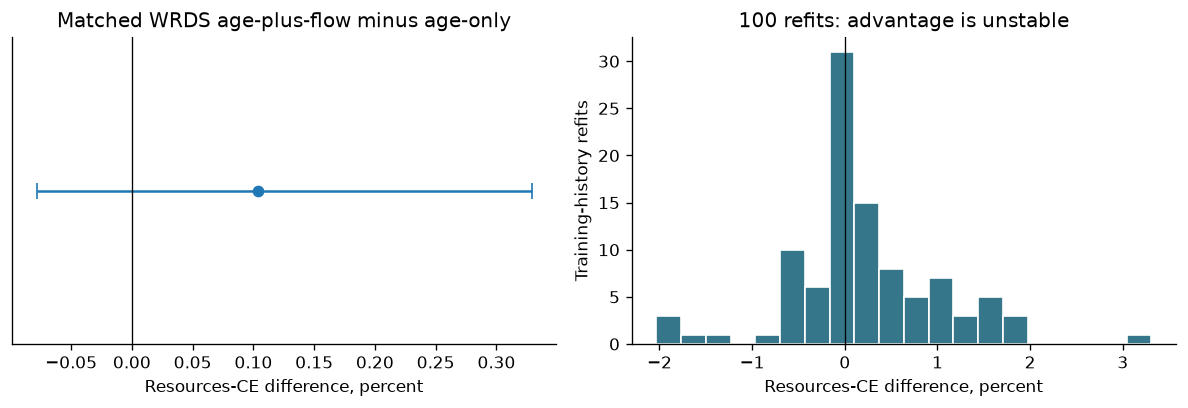

,dataset,window,withdrawal_rate,best_success,all_equity_success,minimum_bond_share,status,conditional_bond_q05,conditional_bond_q95,bootstrap_infeasible_fraction,run_id,catalog_hash
2,public,long,0.05,0.8639,0.8634,NaN,no_feasible_allocation,NaN,NaN,1.000000,d8c0ccdb5bc87defc7b6,3bbcce4a7278f089
6,public,modern,0.05,0.9131,0.9131,0.0,no_bonds_needed,0.00,0.00,0.000000,6ff862dde136e0dcc811,3bbcce4a7278f089
10,public,early,0.05,0.8923,0.8213,NaN,no_feasible_allocation,0.50,0.50,0.996667,0022526d6e21f6d3bede,3bbcce4a7278f089
14,public,recent,0.05,0.9760,0.9760,0.0,no_bonds_needed,0.00,0.00,0.000000,7611a3ec4f17da7523d5,3bbcce4a7278f089
18,treasury_only,long,0.05,0.8647,0.8625,NaN,no_feasible_allocation,NaN,NaN,1.000000,f9bd3b164a72171b66eb,cac766f9337d97dc
22,treasury_only,modern,0.05,0.9126,0.9124,0.0,no_bonds_needed,0.00,0.00,0.000000,5989a1b0cc787cb5a2a5,cac766f9337d97dc
26,treasury_only,early,0.05,0.9071,0.8321,0.4,identified,0.35,0.45,0.003333,956868fe978aa78e2b5b,cac766f9337d97dc
30,treasury_only,recent,0.05,0.9768,0.9768,0.0,no_bonds_needed,0.00,0.00,0.000000,0e6c834d0705fa2b5fb0,cac766f9337d97dc
34,wrds,long,0.05,0.8565,0.8536,NaN,no_feasible_allocation,NaN,NaN,1.000000,5ed2a2bb125f27cca2cb,c1f8e3775eab9dd7
38,wrds,modern,0.05,0.8873,0.8864,NaN,no_feasible_allocation,NaN,NaN,1.000000,ee4f60305754609b50ab,c1f8e3775eab9dd7


In [10]:
extended=json.loads((WRDS/'wrds_extended_runs.json').read_text())
signed=json.loads((WRDS/(extended['signed_flow']['run_id']+'.json')).read_text())
delta=signed['policies']['oos_full_vs_age']
refits=pd.read_csv(WRDS/'robustness/history_refit_scores.csv')
refits=refits[refits.policy.eq('full')].relative_resources_ce
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
axes[0].errorbar([delta['delta']*100],[0],xerr=[[100*(delta['delta']-delta['lo'])],[100*(delta['hi']-delta['delta'])]],fmt='o',capsize=5)
axes[0].axvline(0,color='black',linewidth=.8);axes[0].set(yticks=[],xlabel='Resources-CE difference, percent',title='Matched WRDS age-plus-flow minus age-only')
axes[1].hist(refits*100,bins=20,color='#36768a',edgecolor='white')
axes[1].axvline(0,color='black',linewidth=.8);axes[1].set(xlabel='Resources-CE difference, percent',ylabel='Training-history refits',title='100 refits: advantage is unstable')
fig.tight_layout();save('07_corrected_market_evidence')
frontier=pd.read_csv(WRDS/'matched_frontier_summary.csv')
display(frontier[frontier.withdrawal_rate.eq(.05)])


### 8.1 Complete legacy-demo re-evaluation after the accounting correction

We also reran the complete archived historical demonstration, including its three forward policies and broad cohort/window/ablation experiments, under engine 2.4. Nine numerical fields change, all in forward CE or unmet-outlay summaries. For the lifecycle-adaptive policy, annual CE changes from $80,249.76 to $80,247.69, mean cumulative unmet outlays from $36,831.84 to $36,842.15, and unmet-outlay CVaR95 from $501,433.51 to $501,574.27. Its no-shortfall probability remains 88.4%. Other numerical fields, including the realized replay and experiments, agree within rtol 1e-10 / atol 1e-9. The corrected output supersedes those nine archived forward numbers; no broader policy superiority follows.

The repeated numerical projection/optimization helpers now use Numba compilation without changing their algorithm or iteration caps. Independent analytical projection, quadratic-optimization and equal-risk-contribution tests accompany the change. A warm six-asset helper microbenchmark is supplied separately; it is not a claim about total application speed.

In [11]:
replay_audit=json.loads((HERE/'engine24_historical_replay_audit.json').read_text())
display(pd.DataFrame(replay_audit['differences']))
display(pd.DataFrame(replay_audit['forward_summary']).T)


,path,before,after,absolute_change
0,/forward/sixty_forty/ce_consumption,82023.282545,82023.268302,-0.014243
1,/forward/sixty_forty/unmet_mean,462.776388,462.902388,0.126000
2,/forward/sixty_forty/unmet_cvar95,9255.527760,9258.047760,2.520000
3,/forward/lifecycle_adaptive/ce_consumption,80249.764798,80247.686266,-2.078533
4,/forward/lifecycle_adaptive/unmet_mean,36831.844185,36842.150185,10.306000
5,/forward/lifecycle_adaptive/unmet_cvar95,501433.508387,501574.268387,140.760000
6,/forward/target_date/ce_consumption,81945.765447,81945.657578,-0.107869
7,/forward/target_date/unmet_mean,2926.593383,2927.405383,0.812000
8,/forward/target_date/unmet_cvar95,58531.867660,58548.107660,16.240000


,available,ce_consumption,p_no_shortfall,unmet_mean,terminal
sixty_forty,True,82023.268302,0.994,462.902388,"[1192549.0, 8250227.0, 25984400.0]"
target_date,True,81945.657578,0.98,2927.405383,"[359745.0, 3004367.0, 8664038.0]"
lifecycle_adaptive,True,80247.686266,0.884,36842.150185,"[0.0, 1251144.0, 4996238.0]"


## 9. International evidence: results and what remains unidentified

**Italy:** SHIW 2016/2022 provides independent microdata. Income/wealth-adjusted older-age willingness is lower in both waves. The adjusted liquidity-coverage advantage persists in 2016 but is inconclusive in 2022. Reference-person and expense definitions differ from SCF. Replication uncertainty follows [Faiella (2008), equation 11](https://www.bancaditalia.it/pubblicazioni/temi-discussione/2008/2008-0662/en_tema_662.pdf).

**India:** [SEBI Investor Survey 2025](https://www.sebi.gov.in/reports-and-statistics/research/jan-2026/investor-survey-2025-_99170.html) provides 91,950 random listing interviews in the primary sample. The oldest recorded cohort is 6.26 percentage points less willing than Gen Z after gender, residence, income, education and state adjustment (state-cluster interval -9.06 to -3.46). Rounded published low-risk shares are reproduced. Age is the most educated household respondent's generation, not exact age. Monthly saving allocations are flows; Indian liquidity capacity is not identified. The smaller main-survey state-cluster interval includes zero.

**European coverage:** Italy, Spain, Germany, France, Netherlands, Austria, Belgium and Portugal have extracted [HFCS](https://www.ecb.europa.eu/stats/ecb_surveys/hfcs/html/index.en.html) 2021/2023 age-group tables for assets, wealth, debt-service burden and budget surplus. Public separate medians do not recover household expense coverage or joint willingness-capacity relations; no division of those medians is performed. Country reference periods are retained.

**China:** the public [CHFS author subset](https://doi.org/10.1371/journal.pone.0296100) has a negative recorded willingness-age relationship, but missing national weights and unresolved unknown/no-risk coding prevent a nationally representative claim. **Japan:** the [public investor subset](https://doi.org/10.1371/journal.pone.0315622) has unresolved risk-score interpretation and selected brokerage coverage. Neither subset identifies comparable liquid-budget capacity. **UK:** [Brooks et al. (2018)](https://doi.org/10.1016/j.irfa.2017.12.008) is reviewed adviser-client evidence; it is not a newly executed national regression. German/Dutch panel evidence from Dohmen et al. is literature context, not a reanalysis of those panels.

The inventory covers **13 countries at different evidence levels**, not 13 equivalent national risk estimates. A cross-country institutional or cultural explanation would require harmonized microdata, comparable populations and measurement checks. Public aggregates cannot substitute for those inputs.

In [12]:
inventory=pd.read_csv(PRIOR/'country_evidence_inventory.csv')
display(inventory)
italy=pd.read_csv(PRIOR/'italy_age_contrasts.csv')
india=pd.read_csv(PRIOR/'india_age_effects.csv')
display(italy[italy.specification.eq('Income and wealth adjustment') & italy.outcome.isin(['any_risk','buffer_ge3'])])
display(india[india['sample'].eq('Random interviews') & india.outcome.eq('oldest_minus_GenZ')])


,country,source,evidence_level,age_willingness,age_financial_resilience,boundary,source_url
0,United States,SCF 2016/2019/2022/2025; SHED supporting evidence,Executed household microdata,Lower willingness across waves and adjustment ...,Older groups have greater expense coverage; po...,Observed 0-10 and ordinal financial willingnes...,https://www.federalreserve.gov/econres/scfinde...
1,Italy,SHIW 2016/2022; HFCS 2021/2023,Executed household microdata and official aggr...,Demographic contrasts inconclusive; income/wea...,Positive demographic expense-coverage contrast...,Different respondent and spending definitions ...,https://www.ecb.europa.eu/stats/ecb_surveys/hf...
2,India,SEBI Investor Survey 2025,Executed public respondent microdata,Oldest cohort less willing than Gen Z in weigh...,"Not identified: saving allocations are flows, ...","Age cohorts, not exact ages; model-based uncer...",https://www.sebi.gov.in/reports-and-statistics...
3,China,CHFS 2019 public author subset,Executed author-provided subset,Lower observed willingness at older ages; unkn...,Not identified from supplied asset totals,No national weights or liquid-balance/spending...,https://doi.org/10.1371/journal.pone.0296100
4,Japan,2023 Rakuten/Hiroshima public investor subset,Executed author-provided subset,Supplied score age contrast estimated; financi...,Not identified from supplied asset/income brac...,Selected brokerage investors; no harmonized to...,https://doi.org/10.1371/journal.pone.0315622
5,Spain,ECB HFCS 2021/2023,Executed official aggregate extraction,Not estimated from acquired respondent data.,"Financial assets, net wealth, debt burden and ...",Research-access microdata needed for comparabl...,https://www.ecb.europa.eu/stats/ecb_surveys/hf...
6,Germany,ECB HFCS 2021/2023,Executed official aggregate extraction,Not estimated from acquired respondent data. P...,"Financial assets, net wealth, debt burden and ...",Research-access microdata needed for comparabl...,https://www.ecb.europa.eu/stats/ecb_surveys/hf...
7,France,ECB HFCS 2021/2023,Executed official aggregate extraction,Not estimated from acquired respondent data.,"Financial assets, net wealth, debt burden and ...",Research-access microdata needed for comparabl...,https://www.ecb.europa.eu/stats/ecb_surveys/hf...
8,Netherlands,ECB HFCS 2021/2023,Executed official aggregate extraction,Not estimated from acquired respondent data. P...,"Financial assets, net wealth, debt burden and ...",Research-access microdata needed for comparabl...,https://www.ecb.europa.eu/stats/ecb_surveys/hf...
9,Austria,ECB HFCS 2021/2023,Executed official aggregate extraction,Not estimated from acquired respondent data.,"Financial assets, net wealth, debt burden and ...",Research-access microdata needed for comparabl...,https://www.ecb.europa.eu/stats/ecb_surveys/hf...


,year,specification,outcome,estimate,se,low,high,p,n
6,2016,Income and wealth adjustment,any_risk,-0.126417,0.036127,-0.197226,-0.055608,0.000467,7211
7,2016,Income and wealth adjustment,buffer_ge3,0.099310,0.041034,0.018884,0.179737,0.015512,7211
15,2022,Income and wealth adjustment,any_risk,-0.138320,0.033040,-0.203078,-0.073562,0.000028,9478
16,2022,Income and wealth adjustment,buffer_ge3,0.027943,0.030109,-0.031071,0.086956,0.353378,9478


,sample,specification,outcome,cohort,estimate,se,low,high,n
4,Random interviews,Cohort only,oldest_minus_GenZ,Baby Boomers minus Gen Z,-0.052185,0.011450,-0.074627,-0.029743,91950
5,Random interviews,Gender and rural residence,oldest_minus_GenZ,Baby Boomers minus Gen Z,-0.061450,0.011499,-0.083988,-0.038911,91950
6,Random interviews,Income education and state,oldest_minus_GenZ,Baby Boomers minus Gen Z,-0.062604,0.011557,-0.085256,-0.039952,91950
7,Random interviews,Income education state; state-cluster sensitivity,oldest_minus_GenZ,Baby Boomers minus Gen Z,-0.062604,0.013772,-0.090624,-0.034584,91950


## 10. Verification, reproducibility and research conclusions

An independent monthly accounting example uncovered a holdings-ledger bug: an explicit zero balance at a continuation boundary was treated as an absent starting state and could restore initial wealth. Engine semantic version **2.4** now distinguishes explicit zero holdings from unspecified holdings. Regression and independent accounting tests cover exhaustion, income recovery, asset losses, trade costs and monthly holdings. The prior matched frontier and signed-flow numerical results reproduce exactly under 2.4; their original dated reports retain the original version metadata. The full historical demonstration is also re-evaluated, with its nine corrected forward summaries documented in Section 8.1 and `ENGINE24_IMPACT_AUDIT.txt`.

The software handoff also upgrades vulnerable frontend dependencies, removes an unnecessary CLI dependency, retains its stylesheet with the MIT license, and replaces the form subscription with React Hook Form useWatch. The final verification file records 124 backend/accounting checks, six household checks, 230 frontend unit tests, 26 final browser tests, production build, audit and report execution. A one-command Windows public-data installation was tested in another fresh clone, including regenerated study outputs and frontend build. The public snapshot lacks gold, so its explicitly labeled ex-gold Permanent Portfolio fallback is used; this is not the classic gold-inclusive portfolio. A local ZIP provides source, executed notebooks, aggregate numerical evidence, citation crosswalks and reproduction instructions. No licensed CRSP/TRACE rows or credentials are included.

**Research conclusion.** Age predicts both observed willingness and defined liquidity coverage across held-out US surveys. The directions differ in raw profiles, and the liquidity interpretation changes with wealth and income structure. Shock-specific budget resilience is more interpretable than an arbitrary composite, but the stress definition remains a modeling choice. The resulting portfolio experiments show where a funding constraint can matter; they do not establish a stable general CE gain, individual investment suitability, or a harmonized international capacity ranking.

**Remaining external dependencies.** Employer installation requires their response/access environment; no response or deployment is represented as completed. No recording or transcript was located in the sources previously searched. Comparable European/Asian capacity estimates require additional research-access microdata and resolved measurement documentation. These boundaries do not prevent reproducing the delivered aggregate notebook or the public-data tests.

**Reproduction entry points:** `research/prepare_household_bridge.py` (official SCF inputs and survey helper scripts); `research/evaluate_age_transport.py` (chronological survey prediction); `research/evaluate_household_bridge.py --dataset public` or `--dataset wrds` (conditional budget experiments); `research/render_followup.py --notebook .../integrated_research.ipynb` (aggregate-only execution). See `REPRODUCE.txt` and `verification.json` in this directory for complete commands and results.